# Image Retrieval with Natural Language

## Data visualization and embedding analysis

The retrieval and fine-tuning parts measure the system. This part looks at the representation the system is built on.

- The geometry of the joint space, through the alignment of paired vectors, the uniformity of the two clouds and the effect of the number of negatives on a ranking.
- Dimensionality reduction of the image space and of the joint image-caption space, with PCA, Isomap and t-SNE, fitted on the same 1000 test images for the zero-shot and for the fine-tuned model.
- Clustering of the image vectors with k-means and Ward agglomeration, scored against the supercategory of the dominant object, plus a caption-clustering consistency check.
- An interactive semantic map of captions around images, and two explanation views for the retrieval decision, Grad-CAM and FovEx, in `app.py`.


## Setup

Both models map every image and every caption to a 512-d vector, and every comparison uses the L2-normalised vector. The zero-shot vectors are the cached ViT-B/32 features of the baseline part, so the numbers here reproduce that part exactly. The fine-tuned model is rebuilt from the delta checkpoint of the fine-tuning part and its vectors are encoded again, because the selected configuration may change the encoders and not only the two projections.

The split is the baseline split, an image-level permutation with seed 100 giving 3000 training, 1000 validation and 1000 test images. The test split is used here because no model was selected on it.


In [1]:
%matplotlib inline
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("svg")
import matplotlib.pyplot as plt

import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from IPython.display import display

sys.path.append(str(Path.cwd() / "Visualization"))
import importlib
import clip_viz as viz

importlib.reload(viz)

SEED = viz.SEED
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"device {viz.DEVICE}")
print(f"torch {torch.__version__}")

import warnings
warnings.filterwarnings("ignore")

device cuda
torch 2.5.0+cu124


## Geometry of the contrastive space

The pre-training objective sees one caption per image in a batch and treats the other captions of the batch as negatives. Two properties of the resulting space follow from that objective. Alignment is the mean distance between the vectors of a positive pair, and uniformity is the spread of the cloud on the sphere,

<!-- prettier-ignore -->
$$ \mathcal{L}_{\text{align}} = \mathbb{E}_{(i,j)\sim P}\left[\|f_I(x_i)-f_T(y_j)\|^2\right],\qquad \mathcal{L}_{\text{unif}} = \log \mathbb{E}_{i\neq j}\left[e^{-2\|z_i-z_j\|^2}\right]. $$

A retrieval decision depends on the margin to the hardest negative, so the gallery is varied from two candidates to the full 1000-image gallery. The small end matches the batch of the loss and the large end matches the retrieval setting.


In [2]:
# cached features, both models
data = viz.load_data()
TAGS = list(viz.TAGS)
EMB = {tag: viz.get_embeddings(tag) for tag in TAGS}

test_idx = data["splits"]["test"]
CAP_TEST = viz.cap_indices(data, test_idx)
OWN_TEST = np.repeat(np.arange(len(test_idx)), 5)
TEST_SUPER = data["supercategory"][test_idx]

print(f"fine tuned tensors {len(viz.load_delta())}")
print(f"test images {len(test_idx)} captions {len(CAP_TEST)}")

rows = []
for tag in TAGS:
    img, txt = EMB[tag]
    metrics = viz.retrieval_metrics(img[test_idx], txt[CAP_TEST], OWN_TEST)
    rows.append({"model": tag, **metrics})
display(pd.DataFrame(rows).round(4))

fine tuned tensors 134
test images 1000 captions 5000


,model,t2i R@1,i2t R@1,t2i R@5,i2t R@5,t2i R@10,i2t R@10,t2i medR,i2t medR
0,zero-shot,0.4826,0.697,0.7812,0.910,0.8880,0.962,2.0,1.0
1,fine-tuned,0.5918,0.763,0.8714,0.925,0.9406,0.970,1.0,1.0


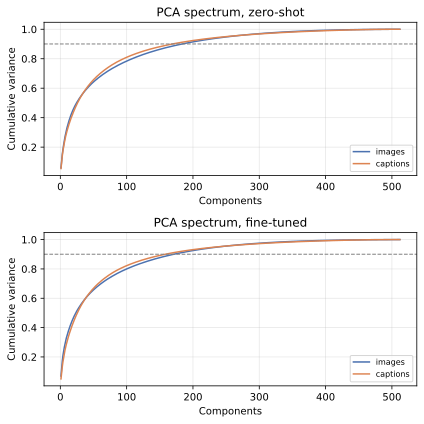

zero-shot images components for 0.9 variance 184
zero-shot captions components for 0.9 variance 169
fine-tuned images components for 0.9 variance 171
fine-tuned captions components for 0.9 variance 159


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(6, 6))
ratios = {}
for ax, tag in zip(axes, TAGS):
    img, txt = EMB[tag]
    ratios[tag] = viz.pca_spectrum(img[test_idx], txt[CAP_TEST])
    img_ratio, txt_ratio = ratios[tag]
    ax.plot(
        np.arange(1, len(img_ratio) + 1),
        np.cumsum(img_ratio),
        color="#4C72B0",
        label="images",
    )
    ax.plot(
        np.arange(1, len(txt_ratio) + 1),
        np.cumsum(txt_ratio),
        color="#DD8452",
        label="captions",
    )
    ax.axhline(0.9, color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"PCA spectrum, {tag}")
    ax.set_xlabel("Components")
    ax.set_ylabel("Cumulative variance")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for tag in TAGS:
    for name, ratio in zip(["images", "captions"], ratios[tag]):
        need = int(np.searchsorted(np.cumsum(ratio), 0.9) + 1)
        print(f"{tag} {name} components for 0.9 variance {need}")

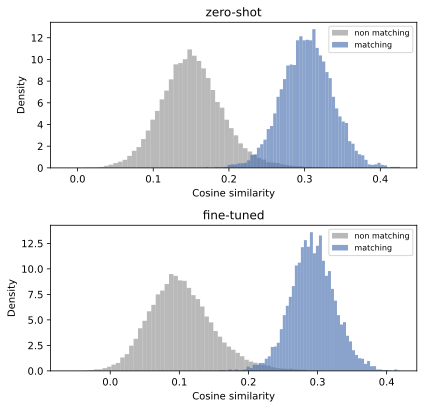

,model,mean positive,mean negative,alignment,image_uniformity,caption_uniformity
0,zero-shot,0.3033,0.1510,0.3033,-2.0557,-1.8815
1,fine-tuned,0.2931,0.1038,0.2931,-1.8940,-1.8387


In [4]:
rng = np.random.default_rng(SEED + 1)
fig, axes = plt.subplots(2, 1, figsize=(6, 5.8))
rows = []
for ax, tag in zip(axes, TAGS):
    img, txt = EMB[tag]
    scores = txt[CAP_TEST] @ img[test_idx].T
    positive = scores[np.arange(len(CAP_TEST)), OWN_TEST]
    negative = scores[OWN_TEST[:, None] != np.arange(len(test_idx))[None, :]]
    sample = rng.choice(negative.ravel(), size=40000, replace=False)
    ax.hist(
        sample, bins=60, density=True, alpha=0.55, color="grey", label="non matching"
    )
    ax.hist(
        positive, bins=60, density=True, alpha=0.65, color="#4C72B0", label="matching"
    )
    ax.set_title(tag)
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    rows.append(
        {
            "model": tag,
            "mean positive": float(positive.mean()),
            "mean negative": float(negative.mean()),
            **viz.geometry_scores(img[test_idx], txt[CAP_TEST], OWN_TEST),
        }
    )
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(4))

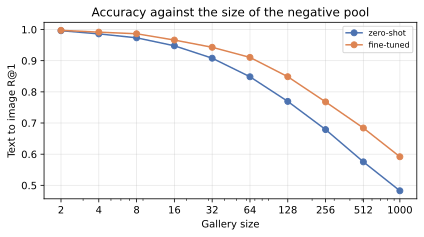

,2,4,8,16,32,64,128,256,512,1000
zero-shot,0.9962,0.9860,0.9734,0.9478,0.908,0.8484,0.7694,0.6790,0.5754,0.4826
fine-tuned,0.9974,0.9916,0.9864,0.9662,0.943,0.9106,0.8486,0.7678,0.6840,0.5918


In [5]:
fig, ax = plt.subplots(figsize=(6, 3.4))
gallery = {}
for tag, colour in zip(TAGS, ["#4C72B0", "#DD8452"]):
    sizes, acc = viz.gallery_accuracy(*EMB[tag], test_idx, CAP_TEST, OWN_TEST)
    gallery[tag] = acc
    ax.plot(sizes, acc, "o-", color=colour, label=tag)
ax.set_xscale("log")
ax.set_xticks(sizes)
ax.set_xticklabels([str(size) for size in sizes])
ax.set_xlabel("Gallery size")
ax.set_ylabel("Text to image R@1")
ax.set_title("Accuracy against the size of the negative pool")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

display(pd.DataFrame(gallery, index=sizes).T.round(4))

## Dimensionality reduction

The same 1000 test images are projected with three methods. PCA is linear and keeps global variance, Isomap keeps geodesic distances on a k-nearest-neighbour graph and t-SNE keeps local neighbourhoods. The first two are read as layout and the third as neighbourhood structure, so distances between separate t-SNE clusters are not metric.


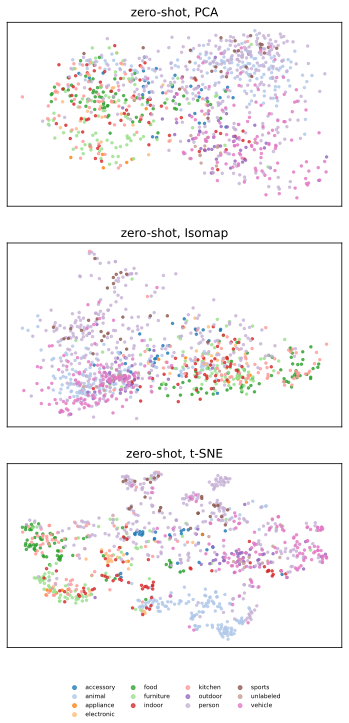

In [6]:
def super_plot(ax, xy, title):
    for i, name in enumerate(sorted(set(TEST_SUPER))):
        mask = TEST_SUPER == name
        ax.scatter(
            xy[mask, 0],
            xy[mask, 1],
            s=6,
            alpha=0.75,
            color=plt.get_cmap("tab20")(i % 20),
            label=name,
        )
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


img_zero = EMB["zero-shot"][0][test_idx]
# pca, isomap, tsne
projections = {
    "PCA": viz.pca_embed(img_zero),
    "Isomap": viz.isomap_embed(img_zero),
    "t-SNE": viz.tsne_embed(img_zero),
}

fig, axes = plt.subplots(3, 1, figsize=(6, 11))
for ax, (name, xy) in zip(axes, projections.items()):
    super_plot(ax, xy, f"zero-shot, {name}")
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    fontsize=6,
    frameon=False,
    markerscale=1.6,
)
plt.subplots_adjust(bottom=0.09, hspace=0.2)
plt.show()

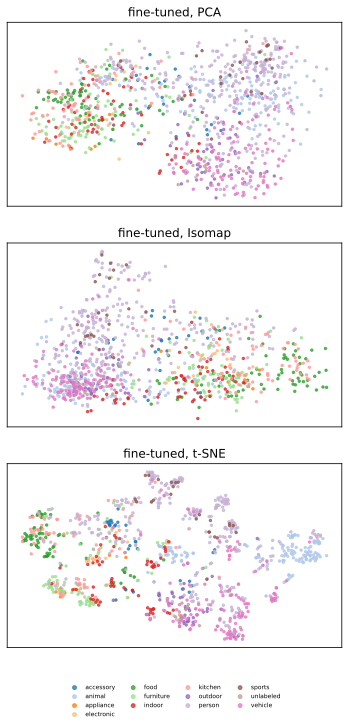

In [7]:
img_tuned = EMB["fine-tuned"][0][test_idx]
projections = {
    "PCA": viz.pca_embed(img_tuned),
    "Isomap": viz.isomap_embed(img_tuned),
    "t-SNE": viz.tsne_embed(img_tuned),
}

fig, axes = plt.subplots(3, 1, figsize=(6, 11))
for ax, (name, xy) in zip(axes, projections.items()):
    super_plot(ax, xy, f"fine-tuned, {name}")
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    fontsize=6,
    frameon=False,
    markerscale=1.6,
)
plt.subplots_adjust(bottom=0.09, hspace=0.2)
plt.show()

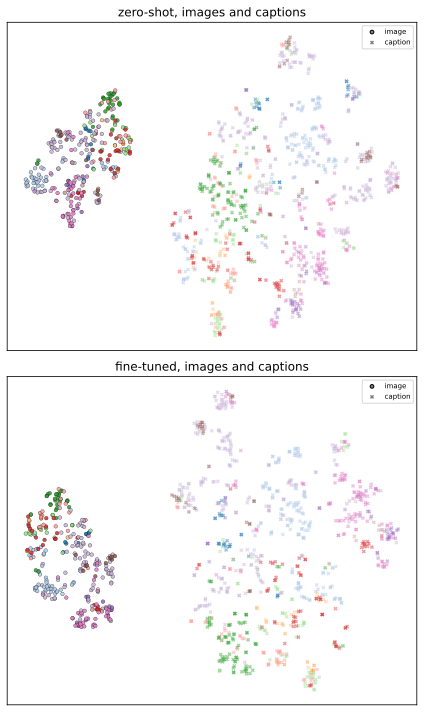

In [8]:
sel_local = np.random.default_rng(SEED + 2).choice(len(test_idx), 300, replace=False)
cap_rows = np.concatenate(
    [
        np.arange(data["offsets"][test_idx[j]], data["offsets"][test_idx[j]] + 3)
        for j in sel_local
    ]
)

fig, axes = plt.subplots(2, 1, figsize=(6, 10))
for ax, tag in zip(axes, TAGS):
    img, txt = EMB[tag]
    mixed = np.vstack([img[test_idx[sel_local]], txt[cap_rows]])
    xy = viz.tsne_embed(mixed)
    kind = np.array(["image"] * len(sel_local) + ["caption"] * len(cap_rows))
    labels = np.concatenate(
        [TEST_SUPER[sel_local], np.repeat(TEST_SUPER[sel_local], 3)]
    )
    for i, name in enumerate(sorted(set(TEST_SUPER))):
        colour = plt.get_cmap("tab20")(i % 20)
        mask = (labels == name) & (kind == "image")
        ax.scatter(
            xy[mask, 0],
            xy[mask, 1],
            s=14,
            alpha=0.85,
            color=colour,
            edgecolor="black",
            linewidth=0.3,
        )
        mask = (labels == name) & (kind == "caption")
        ax.scatter(xy[mask, 0], xy[mask, 1], s=9, alpha=0.45, color=colour, marker="x")
    ax.set_title(f"{tag}, images and captions")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.scatter([], [], s=14, color="grey", edgecolor="black", label="image")
    ax.scatter([], [], s=9, color="grey", marker="x", label="caption")
    ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

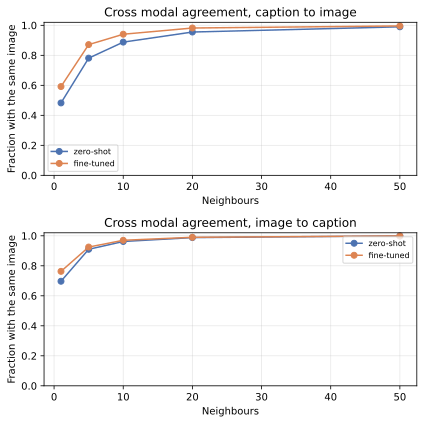

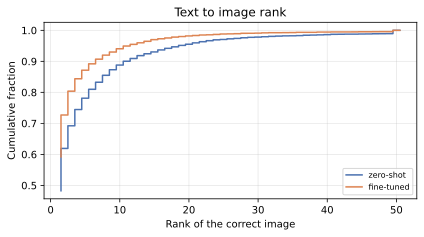

In [9]:
ks = [1, 5, 10, 20, 50]
fig, axes = plt.subplots(2, 1, figsize=(6, 6))
for ax, direction in zip(axes, ["caption to image", "image to caption"]):
    for tag, colour in zip(TAGS, ["#4C72B0", "#DD8452"]):
        _, cap_to_img, img_to_cap = viz.knn_agreement(
            *EMB[tag], test_idx, CAP_TEST, OWN_TEST, ks
        )
        values = cap_to_img if direction == "caption to image" else img_to_cap
        ax.plot(ks, values, "o-", color=colour, label=tag)
    ax.set_xlabel("Neighbours")
    ax.set_ylabel("Fraction with the same image")
    ax.set_title(f"Cross modal agreement, {direction}")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.4))
for tag, colour in zip(TAGS, ["#4C72B0", "#DD8452"]):
    img, txt = EMB[tag]
    scores, order, rank = viz.rank_rows(img[test_idx], txt[CAP_TEST], OWN_TEST)
    counts, edges = np.histogram(np.clip(rank, 1, 50), bins=np.arange(1, 52) - 0.5)
    ax.step(
        edges[1:],
        np.cumsum(counts) / counts.sum(),
        where="pre",
        color=colour,
        label=tag,
    )
ax.set_xlabel("Rank of the correct image")
ax.set_ylabel("Cumulative fraction")
ax.set_title("Text to image rank")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Clustering

K-means is fitted on the image vectors for k in {8, 13, 40}, where 13 matches the number of supercategories, and Ward agglomeration is fitted for k=13 as a second partition. Partitions are scored with NMI, ARI, purity and silhouette, and the labels are used only for scoring. Captions are clustered separately, and the agreement between a caption cluster and the image cluster of its own image measures how much of the shared space survives the separate clustering.


In [10]:
cluster_labels = {}
rows = []
for tag in TAGS:
    features = EMB[tag][0][test_idx]
    for k in [8, 13, 40]:
        metrics, pred = viz.cluster_report(features, TEST_SUPER, k)
        rows.append({"model": tag, "method": "k-means", "k": k, **metrics})
        if k == 13:
            cluster_labels[(tag, "k-means")] = pred
    metrics, pred = viz.cluster_report(features, TEST_SUPER, 13, method="ward")
    rows.append({"model": tag, "method": "ward", "k": 13, **metrics})
    cluster_labels[(tag, "ward")] = pred
display(pd.DataFrame(rows).round(4))

,model,method,k,nmi,ari,purity,silhouette
0,zero-shot,k-means,8,0.3429,0.1808,0.486,0.0664
1,zero-shot,k-means,13,0.3550,0.1673,0.526,0.0628
2,zero-shot,k-means,40,0.3696,0.0917,0.573,0.0561
3,zero-shot,ward,13,0.3351,0.1402,0.508,0.0438
4,fine-tuned,k-means,8,0.3776,0.2283,0.547,0.0735
5,fine-tuned,k-means,13,0.3772,0.1883,0.564,0.0745
6,fine-tuned,k-means,40,0.3911,0.0984,0.602,0.0741
7,fine-tuned,ward,13,0.3878,0.2048,0.555,0.0621


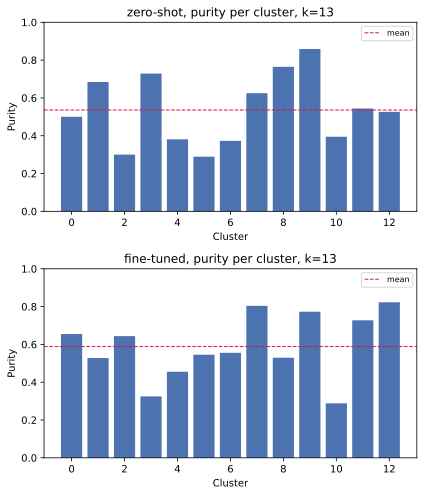

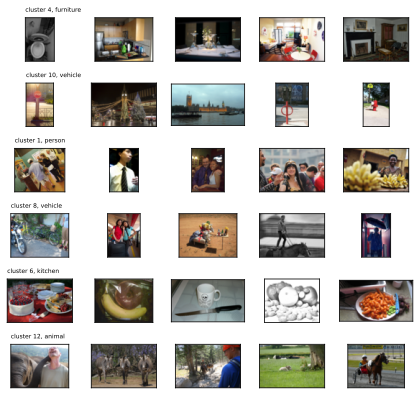

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(6, 7))
for ax, tag in zip(axes, TAGS):
    pred = cluster_labels[(tag, "k-means")]
    scores = []
    for cluster in range(13):
        mask = pred == cluster
        scores.append(Counter(TEST_SUPER[mask]).most_common(1)[0][1] / mask.sum())
    ax.bar(np.arange(13), scores, color="#4C72B0")
    ax.axhline(
        np.mean(scores), color="crimson", linestyle="--", linewidth=1, label="mean"
    )
    ax.set_title(f"{tag}, purity per cluster, k=13")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Purity")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

pred = cluster_labels[("fine-tuned", "k-means")]
sizes = np.bincount(pred)
big = np.argsort(-sizes)[:6]

fig, axes = plt.subplots(6, 5, figsize=(6, 5.6))
for row, cluster in enumerate(big):
    members = np.where(pred == cluster)[0][:5]
    title = Counter(TEST_SUPER[members]).most_common(1)[0][0]
    for col in range(5):
        ax = axes[row, col]
        ax.set_xticks([])
        ax.set_yticks([])
        if col < len(members):
            image = Image.open(data["image_paths"][test_idx[members[col]]]).convert(
                "RGB"
            )
            image.thumbnail((120, 120))
            ax.imshow(image)
        if col == 0:
            ax.set_title(f"cluster {cluster}, {title}", fontsize=6, loc="left")
plt.tight_layout()
plt.show()

In [12]:
rows = []
for tag in TAGS:
    img, txt = EMB[tag]
    rows.append(
        {
            "model": tag,
            **viz.caption_cluster_consistency(
                img[test_idx], txt[CAP_TEST], OWN_TEST, 13
            ),
        }
    )
display(pd.DataFrame(rows).round(4))

,model,caption_agreement,image_mutual_info
0,zero-shot,0.5472,0.4797
1,fine-tuned,0.6672,0.5791


## Interactive semantic map

The interactive map holds the 1000 test images and their 5000 captions in one t-SNE layout, fitted on both modalities together. Selecting an image marks its own captions and the captions of its nearest images, so the captions around one image can be read at once. The layout is stored in `viz_assets` and served by `app.py`, together with the two explanation views.


map images 1000 captions 5000


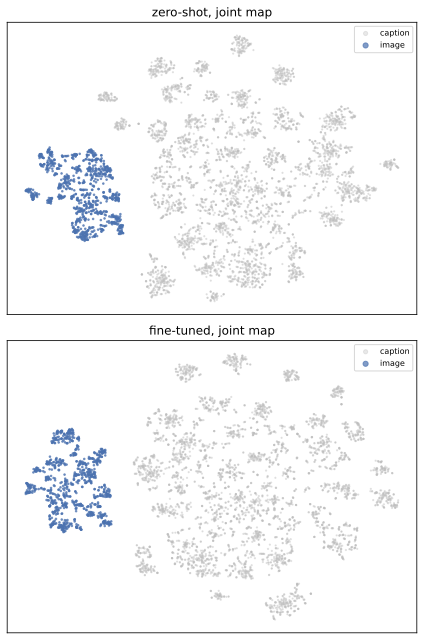

In [13]:
# joint map, saved assets
assets = viz.build_semantic_assets()
print(
    f"map images {assets['zero-shot']['img_xy'].shape[0]} captions {assets['zero-shot']['txt_xy'].shape[0]}"
)

fig, axes = plt.subplots(2, 1, figsize=(6, 9))
for ax, tag in zip(axes, TAGS):
    image_xy = assets[tag]["img_xy"]
    text_xy = assets[tag]["txt_xy"]
    ax.scatter(
        text_xy[:, 0], text_xy[:, 1], s=2, alpha=0.35, color="#bdbdbd", label="caption"
    )
    ax.scatter(
        image_xy[:, 0], image_xy[:, 1], s=3, alpha=0.7, color="#4C72B0", label="image"
    )
    ax.set_title(f"{tag}, joint map")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(fontsize=8, markerscale=3)
plt.tight_layout()
plt.show()

## Grad-CAM for a caption query

Grad-CAM takes the 49 patch tokens that enter the last ViT block, weights every channel by the gradient of the target score and sums over the channels,

<!-- prettier-ignore -->
$$ L = \sum_{k}\frac{\partial s}{\partial A_{k}}\odot A_{k}, $$

where the target score $s$ is the cosine between the image vector and one candidate caption, $A_k$ is channel $k$ of a patch token and the sum runs over the 768 channels of the last block. The map is normalised to [0,1] over the 49 tokens, so a token is bright when its features raise the score of the caption. It is rendered on the 224x224 input and compared between the two models for the same caption. A deletion readout hides one grid cell at a time and records the change of the target score, which checks the map against the behaviour of the model itself.

Grad-CAM is used because it needs one backward pass per query, it gives a map for any candidate caption without a classifier head and it makes the two models directly comparable on the same query. Its weakness is that a large gradient does not prove that the region is necessary, so the deletion readout is reported next to the map.


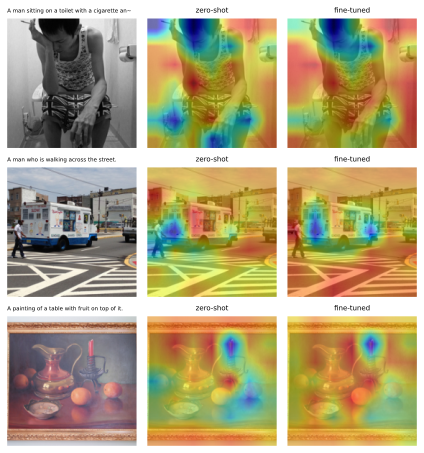

examples [474095, 393226, 184791]


In [14]:
# grad cam, target caption
models = {tag: viz.get_model(tag) for tag in TAGS}
examples = np.random.default_rng(SEED + 4).choice(len(test_idx), 3, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(6, 6.4))
for row, local in enumerate(examples):
    image_idx = int(test_idx[local])
    caption = data["captions_by_image"][data["image_ids"][image_idx]][0]
    rgb = viz.rgb_tensor(image_idx)
    axes[row, 0].imshow(rgb.permute(1, 2, 0).numpy())
    axes[row, 0].set_title(viz.short(caption, 46), fontsize=5.5, loc="left")
    for col, tag in enumerate(TAGS, start=1):
        model = models[tag]
        text_emb = torch.tensor(
            viz.embed_texts(model, [caption]), dtype=torch.float32, device=viz.DEVICE
        )
        cam = viz.gradcam_for(model)(
            viz.normalized(rgb.unsqueeze(0).to(viz.DEVICE)), text_emb[0]
        )
        axes[row, col].imshow(viz.cam_overlay(rgb, cam))
        axes[row, col].set_title(tag, fontsize=7)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"examples {[int(data['image_ids'][i]) for i in test_idx[examples]]}")

## FovEx for CLIP

FovEx optimises a fixation sequence instead of weighting gradients. The periphery is a Gaussian blur and the visible input keeps a Gaussian window around the current fixation,

<!-- prettier-ignore -->
$$ s_t = G_t\odot x + (1-G_t)\odot \bar{x},\qquad G_t=\sum_{j=0}^{t}\beta^{j}\mathcal{G}(f_{t-j},\sigma_f^2), $$

<!-- prettier-ignore -->
$$ f_{t+1} = f_t-\lambda\nabla_{f_t}\mathcal{L}\left(b(s_t),y\right), $$

where the target $y$ is one caption of the candidate set and the loss is the cross entropy of the scaled cosine scores. Ten fixations with twenty sign-gradient steps and the paper default blur parameters are used. The attribution map is the normalised sum of the fixation Gaussians. The interactive view renders the foveated input of every grid cell, so the hover shows what the model can still recognise from that gaze.

FovEx is used because it is model agnostic, it needs only forward and backward passes through the frozen encoder, and its fixation sequence shows how much of the image must stay visible before the caption is recognised. The two methods answer different questions: Grad-CAM shows where the gradient is large, FovEx shows which region has to be in focus.


zero-shot top caption 1 target probability 0.815
fine-tuned top caption 1 target probability 0.776


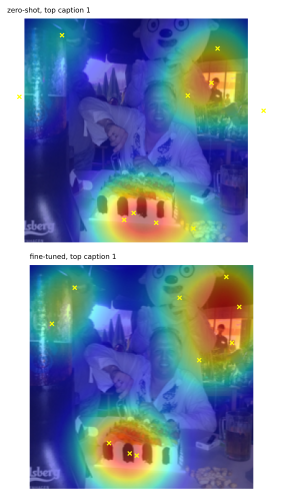

image 156643
1 Person cutting cake at a theme restaurant characters in background.
2 A man cuting a piece of cake while a person in costume stands behind him.
3 A smiling man sitting by a very nice looking cake.
4 a man that is sitting down cutting a cake
5 a man is carving into a cake covered in fruit
6 a man is holding a plate and smiling happily
7 A man sitting at a table eating a hamburger and fries.
8 two people at a bar holding drinks 
9 am empty bowl and three empty beer bottles in front of a man
10 A man and a woman cutting up a small white cake.


In [15]:
# fovex, ten fixations
local = int(np.random.default_rng(SEED + 5).choice(len(test_idx)))
image_idx = int(test_idx[local])
texts, near = viz.caption_candidates(image_idx)

fig, axes = plt.subplots(2, 1, figsize=(6, 7))
for ax, tag in zip(axes, TAGS):
    out = viz.fovex_run(models[tag], image_idx, texts, 0, seed=SEED)
    base = (out["rgb"].permute(1, 2, 0).numpy() * 255).clip(0, 255).astype(np.uint8)
    ax.imshow(viz.overlay_heatmap(base, out["heat"], 0.5))
    x = (out["scan"][:, 1] + 1) * 0.5 * (viz.SIZE - 1)
    y = (out["scan"][:, 0] + 1) * 0.5 * (viz.SIZE - 1)
    ax.plot(x, y, "x", color="yellow", markersize=4, markeredgewidth=1.2)
    ax.set_title(
        f"{tag}, top caption {int(out['sims'].argmax()) + 1}", fontsize=7, loc="left"
    )
    ax.axis("off")
    print(
        f"{tag} top caption {int(out['sims'].argmax()) + 1} target probability {out['probs'][0]:.3f}"
    )
plt.tight_layout()
plt.show()

print(f"image {data['image_ids'][image_idx]}")
for i, text in enumerate(texts):
    print(f"{i + 1} {text}")

## Discussion

### Geometry

Fine-tuning raises text-to-image R@1 from 0.4826 to 0.5918 and image-to-text R@1 from 0.6970 to 0.7630 on the test split, and the median rank of the harder direction falls from 2 to 1. The values match the selected fine-tuning run (0.5950 and 0.7660) within 0.004, and the gap comes from the text pipeline, where the raw captions used here replace the normalised prompt used there.

The gain is not an alignment gain. The mean positive cosine falls from 0.3033 to 0.2931, while the mean negative cosine falls from 0.1510 to 0.1038, so the positive-negative margin rises from 0.1523 to 0.1893. Both clouds are also more spread: image uniformity rises from -2.0557 to -1.8940 and caption uniformity from -1.8815 to -1.8387. The contrastive loss is dominated by the negatives, and 15000 captions are enough to separate non-matching pairs without lifting the positives.

The PCA spectrum shows that the 512 dimensions are far from independent: 184 components carry 90 percent of the image variance in the zero-shot space and 171 in the fine-tuned space. The fine-tuned space needs fewer components for the same variance, so the update concentrates the spectrum slightly rather than spreading it, and a two-dimensional map keeps only a small part of either space.

The gallery curve isolates where the gain comes from. With two candidates the two models are almost tied, 0.9962 against 0.9974, and the gap grows with the pool: 0.9860 against 0.9916 at 4, 0.9478 against 0.9662 at 16, 0.8484 against 0.9106 at 64, 0.7694 against 0.8486 at 128, 0.6790 against 0.7678 at 256, 0.5754 against 0.6840 at 512 and 0.4826 against 0.5918 at 1000. More than half of the final 10.9 points is already present at 64 candidates, 0.0622 of 0.1092, and the gap saturates at 512. The fine-tuned model separates the candidates that share the scene rather than the easy ones.

### Dimensionality reduction

PCA preserves global variance, Isomap keeps geodesic distances on a 15-neighbour graph and t-SNE keeps local neighbourhoods. The three panels of each model use the same points and the same seed, so a difference between the two models comes from the representation and not from the projection.

None of the projections separates the supercategories into disjoint modes, which is expected from 184 components for 90 percent variance. The colours are also coarse: the label is the supercategory of the dominant object, so a scene with a person and a dog carries one label.

The joint panel puts the captions of an image next to its vector. The neighbourhood search is the retrieval itself, so at k=1 the fraction of captions whose nearest image is their own is the text-to-image R@1, 0.4826 for zero-shot and 0.5918 for fine-tuned; at k=5 the values are 0.7812 and 0.8714, and at k=10 0.8880 and 0.9406. The curve therefore rises monotonically and the two modalities share one neighbourhood structure.

### Clusters

At k=13, the number of supercategories, k-means gives NMI 0.3550, ARI 0.1673, purity 0.5260 and silhouette 0.0628 for the zero-shot space, and NMI 0.3772, ARI 0.1883, purity 0.5640 and silhouette 0.0745 for the fine-tuned space. Ward gives the same direction, from NMI 0.3351 to 0.3878, ARI 0.1402 to 0.2048, purity 0.508 to 0.555 and silhouette 0.0438 to 0.0621. The image space becomes more separable by object category after fine-tuning.

The scores depend on k. NMI and purity rise with k for both spaces, from 0.3429 to 0.3696 and 0.486 to 0.573 for zero-shot and from 0.3776 to 0.3911 and 0.547 to 0.602 for fine-tuned, because a finer partition can always fill a pure cell. ARI falls at k=40, to 0.0917 and 0.0984, so the 40-cluster partition is finer than the label and should not be read as a better model of the supercategory.

Silhouette stays below 0.08 in every setting, so the clusters overlap and a supercategory is a region of a continuum rather than a separated mode. Fine-tuning improves the separation without creating clean boundaries.

The caption partition follows the image partition more closely after fine-tuning. The agreement between a caption cluster and the image cluster of its own image rises from 0.5472 to 0.6672, and the mutual information between the two partitions from 0.4797 to 0.5791. Since the mean positive cosine falls at the same time, the improvement is in the neighbourhood structure and not in the global alignment.

### Explanations

The explanation target is one of ten candidate captions: the five reference captions of the image and one caption from each of the five nearest images, chosen by zero-shot image similarity. The decision is a ten-way ranking, and the same set is used for both models.

On image 156643 with the first reference caption, both models rank that caption first among the ten candidates, and the target probability is 0.815 for the zero-shot model and 0.776 for the fine-tuned model. Both FovEx maps put their hottest region on the cake on the table, which is the object named in the caption, and the fine-tuned map adds mass on the mascot behind the person, which the caption names as the characters in the background. The lower probability of the fine-tuned model is consistent with the geometry section: its positive similarities are on average slightly lower, 0.2931 against 0.3033, and its space is more uniform, so the softmax over ten candidates is flatter. This probability is not comparable to the retrieval rank.

Grad-CAM uses the gradient-weighted activation of the 49 patch tokens entering the last block, so a token is bright when its features raise the score of the caption. The maps differ between the two models, because the last four blocks of both towers are fine-tuned. They are also coarse: at 7x7 a cell covers 32x32 pixels, so a small object is averaged with its surroundings. In the toilet example the warm mass sits on the person, which is the subject of the caption. In the street example the cell that contains the walking man is cold while the road and the ice cream truck are warm, and in the still life the warm mass follows the table and the vessels. At this granularity the map is not a reliable object localiser, and the deletion readout in `app.py` is the quantitative check.

### Limits

FovEx optimises the fixation that preserves the target caption, so its map is closer to an insertion score than to a deletion score, and the cell deletion readout of the Grad-CAM view is used as an independent check.
The cluster labels come from the supercategory of the dominant object, which is coarse for scenes with several objects, so purity and NMI are lower bounds on the semantic organisation of the space.
The t-SNE layout depends on perplexity and random initialisation, so only cluster structure is read and not exact distances.
The explanation target is one of ten candidate captions, so it explains a local ranking decision and not the full 1000-image retrieval, and the FovEx probability is a softmax over that set.
The Grad-CAM map comes from a 7x7 patch grid upsampled to 224, so it cannot localise below about 32 pixels.
The fine-tuned model was selected on the COCO validation split; the test split is reported here and matches the selection notebook within 0.004.
